In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import CHive
import scanpy as sc
import numpy as np
import pandas as pd
import scvi
import matplotlib.pyplot as plt

scvi.settings.dl_num_workers = 0
scvi.settings.num_threads = 16

%matplotlib inline
%load_ext autoreload
%autoreload 2

### read data

Normalize the input data (e.g., log or library size normalization) to make it suitable for MSE loss

In this dataset, perturbations were introduced exclusively in the target dataset: a subset of Cell Type 1 was perturbed in the first 20 genes, and a subset of Cell Type 3 was perturbed in genes 20 to 40. Additionally, the perturbed cells exhibited localized spatial clustering. The corresponding background dataset remained unperturbed, serving as a control for contrastive analysis.


In [ ]:
### cause we use the mse loss, we need to normalize the data
adata = sc.read_h5ad("/home/zhaoyu/zhaoyu_disco/project/chvgae/our/code_for_github/data/spatial_simu_all.h5ad")
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 10368 × 500
    obs: 'pop', 'id', 'perturb1', 'perturb2', 'label', 'index', 'dataset', 'group', 'perturb'
    uns: 'log1p'
    obsm: 'spatial'

Before training, we need to inform C-HIVE which cells originate from the background (i.e., control cells) and which are target cells (i.e., perturbed).
This is indicated by the label column, where 1 denotes target cells and 0 denotes background cells.
Since we need to construct a graph for each slice, the corresponding sample ID for each cell must also be provided.

### train model

In [3]:
layer=3
scvi.settings.seed = 42
CHive.model.CHive.setup_anndata(adata, design=['label'], sample_id="dataset")
model = CHive.model.CHive(adata, n_layer=layer, sample_id="dataset", design="label", knn=8)
model.train(accelerator='gpu')

adata.obsm[f"X_CHive_BG"] = model.get_latent_representation(layer=-2)
adata.obsm[f"X_CHive_Salient"] = model.get_latent_representation()

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA RTX A6000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████| 400/400 [23:18<00:00,  3.69s/it, v_num=1, train_loss_step=168, train_loss_epoch=158]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [23:18<00:00,  3.50s/it, v_num=1, train_loss_step=168, train_loss_epoch=158]


The X_CHive_BG, called the background variables, are shared across background and target cells. 
The X_CHive_Salient, called the salient variables, are only active in target cells and are fixed at 0 for background cells.

### clustering

Given that gene expression variation across cell types exists in both the target and background datasets, an ideal common representation should accurately capture cell-type identity while remaining unaffected by target-specific perturbations. 

Visualizing common representations, we can find that cells separate by cell types, and background dataset and target dataset are mixed well.

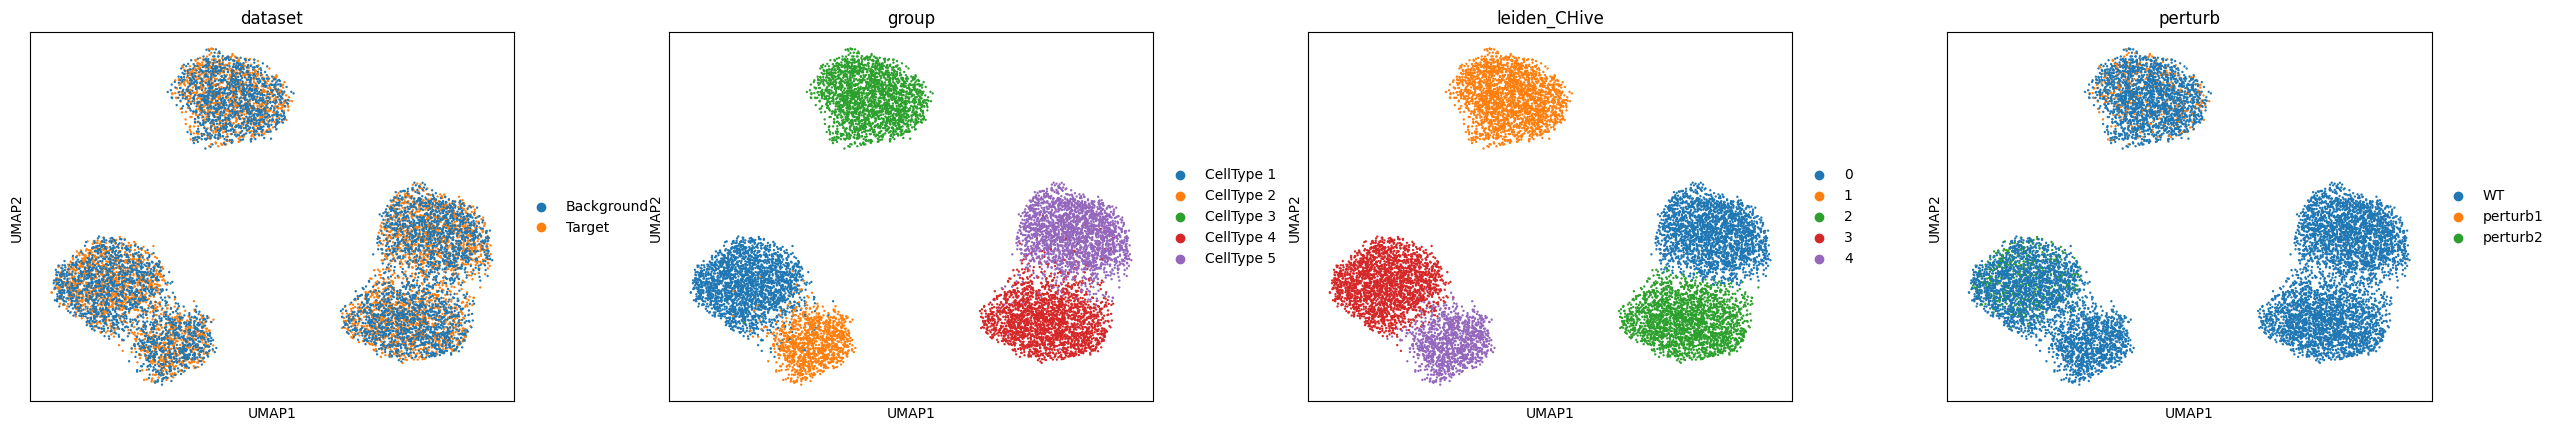

In [4]:
sc.pp.neighbors(adata, use_rep="X_CHive_BG")
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5)
adata.obs["leiden_CHive"] = adata.obs["leiden"]
sc.pl.umap(adata, color=["dataset",  "group", "leiden_CHive", "perturb"], 
                wspace=0.2, ncols=4)

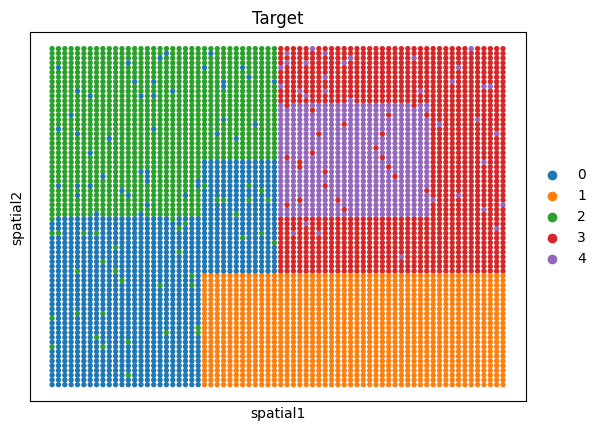

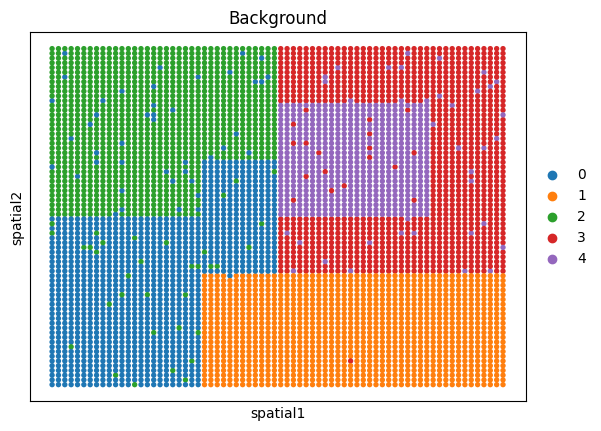

In [5]:
for sample in list(set(adata.obs["dataset"])):
    tmp = adata[adata.obs["dataset"] == sample]
    sc.pl.embedding(tmp, basis="spatial", color=['leiden_CHive'], title=sample, size=60)

Visualizing salient representations, we can find that cells are separate by perturb type,  highlighting target-specific signals.

The salient latent space is designed to isolate perturbation-specific variation within the target dataset, while maintaining uniform mixing among unperturbed wild-type (WT) cell types—specifically, Cell Types 2, 4, and 5.

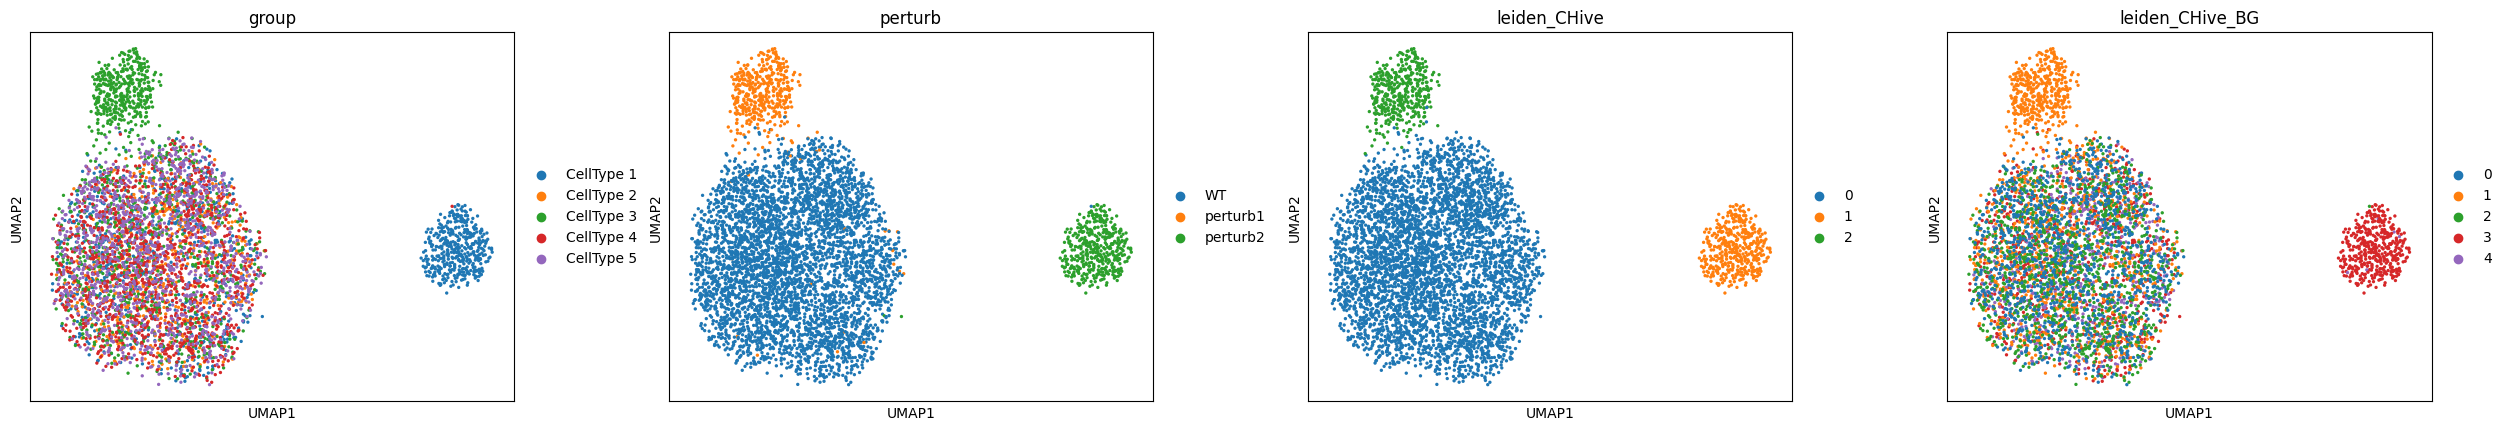

In [6]:
target_adata = adata[adata.obs.label == 1]
target_adata.obs["leiden_CHive_BG"] = adata[target_adata.obs_names, ].obs["leiden_CHive"]
sc.pp.neighbors(target_adata, use_rep="X_CHive_Salient")
sc.tl.umap(target_adata)
sc.tl.leiden(target_adata, resolution=0.2)
target_adata.obs["leiden_CHive"] = target_adata.obs["leiden"]
sc.pl.umap(target_adata, color=["group", "perturb", "leiden_CHive", "leiden_CHive_BG"], wspace=0.2, ncols=4)

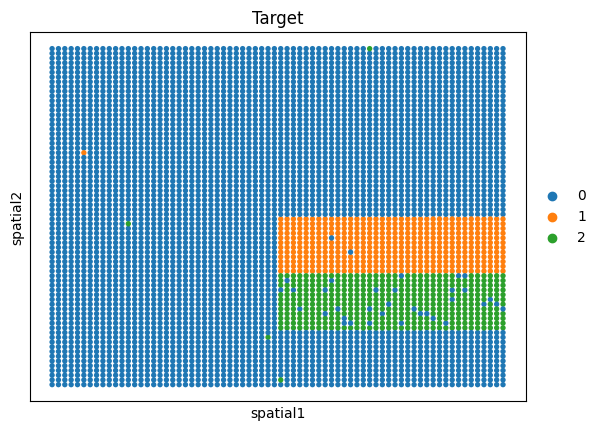

In [7]:
for sample in list(set(target_adata.obs["dataset"])):
    tmp = target_adata[target_adata.obs["dataset"] == sample]
    sc.pl.embedding(tmp, basis="spatial", color=['leiden_CHive'], title=sample, size=60)

### Interpretability

To improve interpretability, we replace the neural networks with linear functions.

In [8]:
model.module.frozen_encoder()
model.module.change_lineardecoder()
model.train(accelerator='gpu')

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████| 400/400 [10:07<00:00,  1.55s/it, v_num=1, train_loss_step=144, train_loss_epoch=150]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [10:07<00:00,  1.52s/it, v_num=1, train_loss_step=144, train_loss_epoch=150]


Each gene's expression can be represented as a weighted sum of several latent variables (denoted as z1, z2, ..., z10), which capture hidden patterns in the data.

Changing the value of z1, for example, will mostly affect the expression levels of genes that have large weights associated with z1 (i.e., large values in the first row of the weight matrix).

By analyzing these weights learned by the C-HIVE model, we can identify which genes are most strongly linked to each latent factor.


In [9]:
loadings = model.get_loadings()
adata.uns['loadings'] = loadings

In [10]:
loadings.head()

,Topic C1,Topic C2,Topic C3,Topic C4,Topic C5,Topic C6,Topic C7,Topic C8,Topic C9,Topic C10,Topic S1,Topic S2,Topic S3,Topic S4,Topic S5,Topic S6,Topic S7,Topic S8,Topic S9,Topic S10
G0,0.206302,-0.174440,-0.000531,0.128284,0.111062,0.071500,0.017745,-0.153735,0.162881,0.094497,-0.358498,0.433021,-0.502026,-0.161844,0.794135,-0.119866,-0.340869,-0.416860,0.369856,0.143211
G1,0.090167,-0.202104,0.253711,0.300516,-0.156428,-0.143797,-0.156282,-0.085400,0.060751,-0.378159,-0.515771,-1.301474,-0.781898,-0.644614,0.941711,-0.970072,0.688868,-1.225997,-0.297035,1.367209
G2,-0.204384,-0.214639,0.017477,0.000872,-0.207566,-0.034841,-0.055108,-0.252433,-0.093875,0.138213,-1.289468,-0.035480,-1.163795,-0.362733,1.188764,1.534780,-0.539049,-0.824915,-0.279495,0.543332
G3,0.003640,-0.065937,0.037942,0.061076,-0.078458,0.034377,-0.019620,0.122990,-0.063626,-0.028241,-0.309604,0.901399,-0.747046,-0.484596,0.739814,0.231658,-0.324453,-0.416207,0.115911,0.329488
G4,-0.022731,0.003756,0.068405,-0.016112,-0.094622,-0.015250,-0.061902,0.050874,-0.059559,-0.056947,-0.170581,0.161536,-1.033384,0.113678,0.967118,-0.116593,0.206068,-0.048181,0.176416,0.466574


We denote the i-th dimension of the common and salient embeddings as Topic Ci and Topic Si, respectively

In [11]:
prefix = "S"
loadings_salient = loadings.filter(like='Topic S')
cell_topic_salient = target_adata.obsm["X_CHive_Salient"]
rotation_results_varimax = CHive.tl.varimax(loadings_salient) 
varimax_loading = rotation_results_varimax['rotloading']
topic_salient_ratation = CHive.tl.get_rotated_scores(cell_topic_salient, rotation_results_varimax['rotmat'])
target_adata.obsm["X_CHive_Salient_rotation"] = topic_salient_ratation


In [12]:
topic_salient_ratation = pd.DataFrame(topic_salient_ratation, 
                                      columns=['Topic '+prefix+str(i) 
                                               for i in range(1, topic_salient_ratation.shape[1]+1)], 
                                      index=target_adata.obs_names)

In [13]:
t_stat_matrix, result =  CHive.tl.t_stat(topic_salient_ratation, target_adata.obs["leiden_CHive"])
result

,Label,Topic,Tvalue
0,0,Topic S3,33.426085
1,1,Topic S3,-97.861200
2,2,Topic S5,65.138931


In [14]:
t_stat_matrix.index = ["Cluster S" + str(int(i) + 1) for i in t_stat_matrix.index]


By performing t-tests between cluster labels and topics in the salient space, we found that Topic S5 was most significantly associated with Cluster S3, while Topic S3 was most significantly associated with Cluster S2.

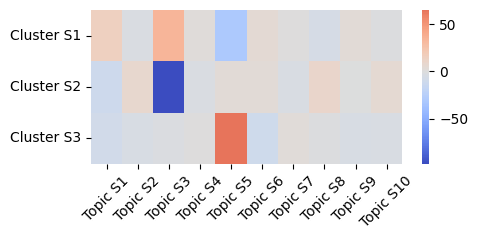

<Axes: >

In [15]:
plt.figure(figsize=(5, 2.5))
CHive.pl.t_stat_heatmap(t_stat_matrix)

In [16]:

loadings_salient_corrected, ranked_genes =  CHive.tl.correct_loadings(varimax_loading, t_stat_matrix, 
                                                                      priority_cluster="Cluster S2")
loadings_salient_corrected.head()

,G0,G1,G2,G3,G4,G5,G6,G7,G8,G9,...,G490,G491,G492,G493,G494,G495,G496,G497,G498,G499
Topic S1,-0.124458,-0.217317,-1.530412,-0.241300,-0.136722,-0.350732,1.459933,-0.437632,-0.218850,-0.466223,...,0.097929,0.028000,0.595574,0.066798,-0.389750,-0.427152,0.147314,0.476568,2.558969,0.089797
Topic S2,0.277153,-0.712626,0.995888,0.698532,0.065388,0.087359,-0.675685,0.247824,-0.072292,-0.116345,...,0.064894,0.027247,-0.112532,0.242743,0.584216,1.586728,-0.348611,-0.067803,0.427542,0.288739
Topic S3,-0.102652,-0.435144,-0.247075,-0.046928,0.264376,0.746049,-0.160572,0.062264,0.047109,0.163865,...,-0.024043,-0.020083,-0.155756,-0.035362,-0.004589,-0.184237,-0.019840,-1.381707,-0.646886,0.147048
Topic S4,0.215097,-0.949145,-0.654825,0.571223,-0.027319,-0.245654,-0.021799,2.593955,-0.039286,-1.131222,...,-0.646399,0.077468,0.866270,0.082622,-0.726878,0.544546,0.096387,-0.170494,0.684717,-0.099875
Topic S5,1.070220,1.421226,1.768603,1.221879,1.456984,0.611543,1.387882,2.360297,1.762657,1.316271,...,0.093079,-0.004734,-0.057608,0.131566,1.547449,-0.146697,0.194435,0.010581,-0.722898,-0.044696


We then identified the top 20 genes most strongly associated with Topic S5 and Topic S3

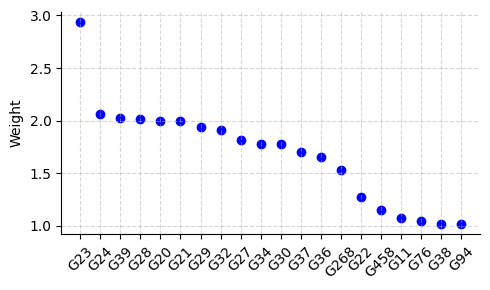

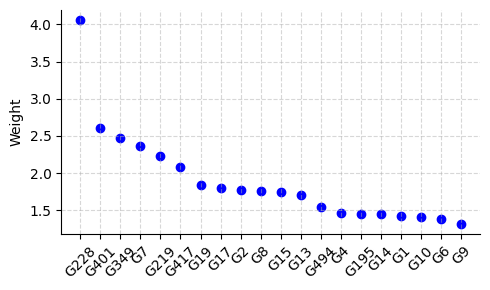

<Axes: ylabel='Weight'>

In [17]:
plt.figure(figsize=(5, 3))
CHive.pl.topic_genes(loadings_salient_corrected, topic_name="Topic S3", top_n=20)
plt.figure(figsize=(5, 3))
CHive.pl.topic_genes(loadings_salient_corrected, topic_name="Topic S5", top_n=20)